In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [2]:
data = load_iris()

df = pd.DataFrame(data.data, columns=data.feature_names)

df["Actual Species"] = data.target
df["Species Name"] = df["Actual Species"].map(
    dict(enumerate(data.target_names))
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Actual Species,Species Name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFlower Species:")
print(data.target_names)

Dataset Shape: (150, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Actual Species     150 non-null    int64  
 5   Species Name       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Actual Species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Actual Species       0
Species Name         0
dtype: int64

Flower Species:
['setosa' 'versicolor' 'virginica']


In [4]:
X = df[["sepal length (cm)", "sepal width (cm)"]]

X.head()

,sepal length (cm),sepal width (cm)
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6


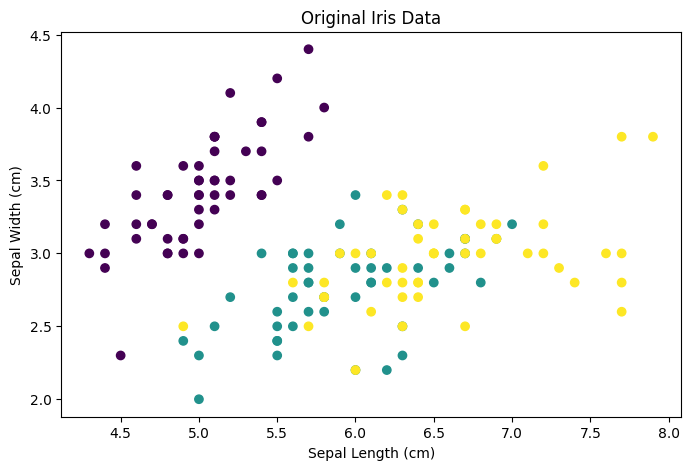

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X["sepal length (cm)"],
    X["sepal width (cm)"],
    c=data.target,
    cmap="viridis"
)

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("Original Iris Data")

plt.savefig("outputs/original_iris_data.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df[data.feature_names])

In [7]:
inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)

c:\Users\hassa\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\hassa\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\hassa\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\hassa\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 966, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\hassa\AppData\Local\Programs\Python\Python310\lib\subp

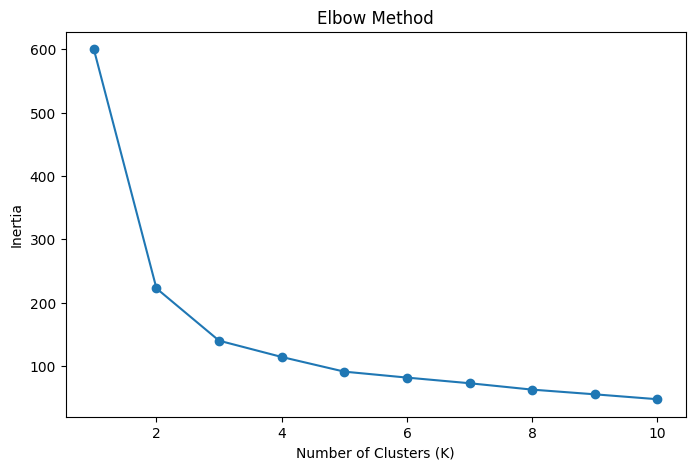

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.savefig("outputs/elbow_method.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Actual Species,Species Name,Cluster
0,5.1,3.5,1.4,0.2,0,setosa,1
1,4.9,3.0,1.4,0.2,0,setosa,1
2,4.7,3.2,1.3,0.2,0,setosa,1
3,4.6,3.1,1.5,0.2,0,setosa,1
4,5.0,3.6,1.4,0.2,0,setosa,1


In [10]:
print("Number of Clusters:", df["Cluster"].nunique())

print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

Number of Clusters: 3

Cluster Distribution:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


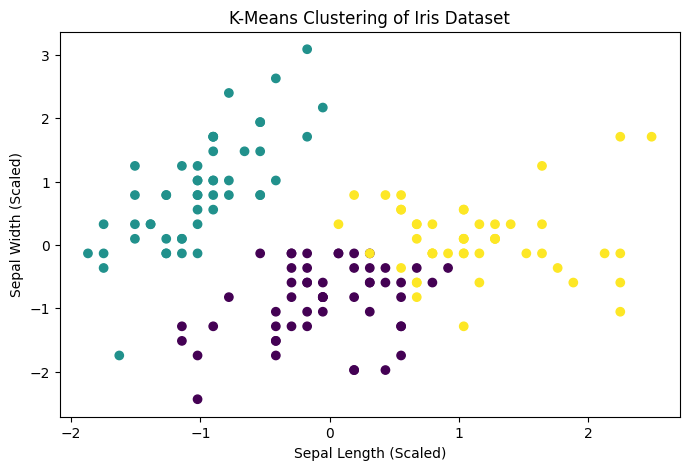

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis"
)

plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")
plt.title("K-Means Clustering of Iris Dataset")

plt.savefig("outputs/kmeans_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("Reduced Shape:", X_pca.shape)

Original Shape: (150, 4)
Reduced Shape: (150, 2)


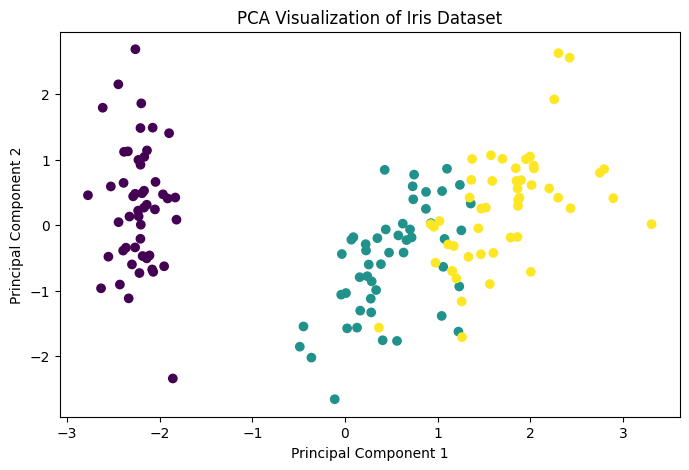

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=data.target,
    cmap="viridis"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")

plt.savefig("outputs/pca_visualization.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[0.72962445 0.22850762]

Total Explained Variance:
0.9581320720000166


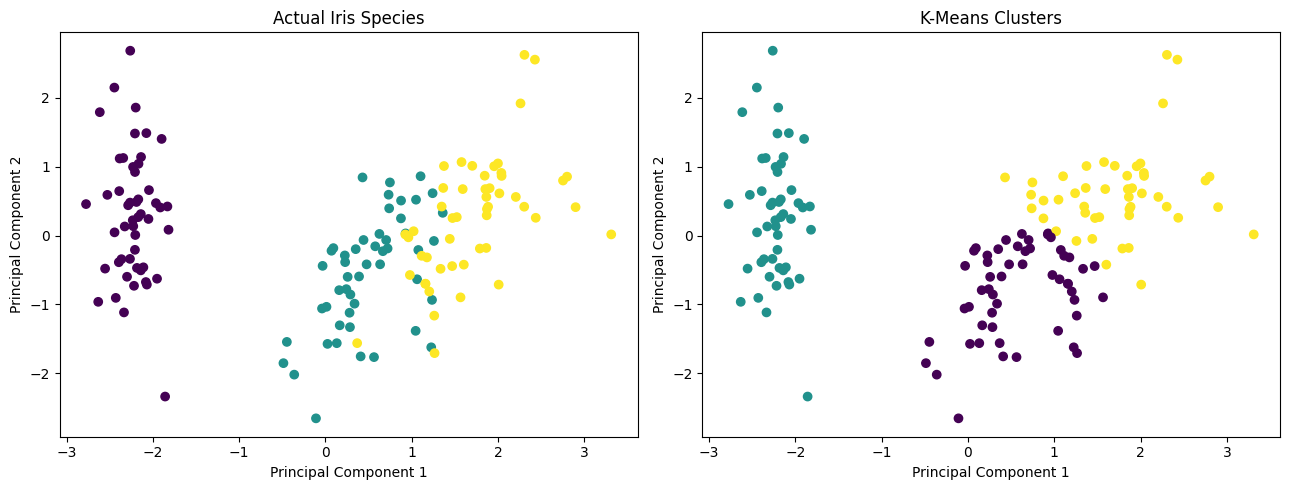

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=data.target,
    cmap="viridis"
)

axes[0].set_title("Actual Iris Species")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis"
)

axes[1].set_title("K-Means Clusters")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.savefig("outputs/species_vs_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
print("IRIS FLOWER CLUSTERING PROJECT")

print("\nTotal Samples:", len(df))

print("Number of Clusters:", df["Cluster"].nunique())

print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

print("\nPCA Explained Variance:")
print(round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

print("\nAll Visualizations Saved Successfully!")

IRIS FLOWER CLUSTERING PROJECT

Total Samples: 150
Number of Clusters: 3

Cluster Distribution:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64

PCA Explained Variance:
95.81 %

All Visualizations Saved Successfully!
